1. Configuração e conexão
Execute este notebook a partir da raiz do projeto ou da pasta analysis/. Ele reutiliza a configuração de conexão do PostgresRepository e as credenciais do .env existente. O PostgreSQL do Docker precisa estar ativo.

In [23]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import psycopg
from psycopg.rows import dict_row
from IPython.display import Markdown, display

# Encontra a raiz do projeto mesmo se o kernel iniciar em analysis/.
project_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "storage" / "postgres_repository.py").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Abra o notebook dentro do projeto ETL-Combustiveis.")

sys.path.insert(0, str(project_root))
from src.storage.postgres_repository import PostgresRepository

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams["figure.figsize"] = (10, 5)

repository = PostgresRepository()
print(f"Projeto: {project_root}")


Projeto: c:\Users\Caio\Desktop\ETL-Combustiveis


2. Extração dos dados da Gold
Usamos a tabela fato e as dimensões para obter observações individuais. Isso permite explorar distribuições e criar agrupamentos diferentes daqueles já disponibilizados pelas views da Gold.

In [35]:
query = """
SELECT
    f.data_coleta,
    l.regiao,
    l.uf,
    l.municipio,
    c.nome AS combustivel,
    c.unidade_medida,
    f.preco_venda,
    f.revenda_id
FROM gold.fato_preco f
JOIN gold.dim_localidade l ON l.id = f.localidade_id
JOIN gold.dim_combustivel c ON c.id = f.combustivel_id
"""

with psycopg.connect(**repository.connection_params, row_factory=dict_row) as conn:
    with conn.cursor() as cursor:
        cursor.execute(query)
        df = pd.DataFrame(cursor.fetchall())

if df.empty:
    raise ValueError("A tabela Gold nao possui registros.")

df["data_coleta"] = pd.to_datetime(df["data_coleta"])
df["preco_venda"] = df["preco_venda"].astype(float)

df["data_referencia"] = (
    df["data_coleta"].dt.to_period("M").dt.to_timestamp()
)

df["mes"] = df["data_referencia"].dt.strftime("%m/%Y")

display(df.drop(columns=["data_referencia"]).head())

,data_coleta,regiao,uf,municipio,combustivel,unidade_medida,preco_venda,revenda_id,mes
0,2025-07-01,NE,AL,DELMIRO GOUVEIA,DIESEL,R$ / litro,6.690,142943,07/2025
1,2025-07-01,N,AP,MACAPA,DIESEL,R$ / litro,6.330,143280,07/2025
2,2025-07-01,NE,BA,IPIRA,DIESEL,R$ / litro,6.900,142092,07/2025
3,2025-07-01,NE,BA,ITAMARAJU,DIESEL,R$ / litro,5.990,143441,07/2025
4,2025-07-01,NE,BA,ITAMARAJU,DIESEL,R$ / litro,5.920,145097,07/2025


3. Visão geral da base
Verificamos a cobertura temporal, o número de UFs, combustíveis e observações.

In [25]:
resumo = pd.DataFrame([{
    "total_coletas": len(df),
    "ufs": df["uf"].nunique(),
    "combustiveis": df["combustivel"].nunique(),
    "data_inicial": df["data_coleta"].min().date(),
    "data_final": df["data_coleta"].max().date(),
}])
display(resumo)

display(
    df.groupby("combustivel", as_index=False)
      .agg(coletas=("preco_venda", "size"), postos=("revenda_id", "nunique"))
      .sort_values("coletas", ascending=False)
)


,total_coletas,ufs,combustiveis,data_inicial,data_final
0,804617,27,6,2025-01-01,2025-12-31


,combustivel,coletas,postos
3,GASOLINA,212423,15422
2,ETANOL,177753,13393
4,GASOLINA ADITIVADA,165691,12348
1,DIESEL S10,144541,11520
0,DIESEL,85969,6640
5,GNV,18240,1245


4. Evolução mensal dos preços
Agrupamos por mês e combustível, calculando média, mínimo, máximo, quantidade de coletas e número de postos distintos. O gráfico compara apenas gasolina e etanol, ambos vendidos por litro.

,mes,combustivel,unidade_medida,preco_medio,preco_minimo,preco_maximo,total_coletas,postos_pesquisados
0,01/2025,DIESEL,R$ / litro,6.131,5.390,7.930,7463,2425
1,01/2025,DIESEL S10,R$ / litro,6.186,5.190,8.990,12317,4061
2,01/2025,ETANOL,R$ / litro,4.369,3.290,6.160,14921,4864
3,01/2025,GASOLINA,R$ / litro,6.184,5.040,8.290,17793,5707
4,01/2025,GASOLINA ADITIVADA,R$ / litro,6.379,5.430,9.490,13795,4508
...,...,...,...,...,...,...,...,...
67,12/2025,DIESEL S10,R$ / litro,6.113,5.390,8.990,13613,4054
68,12/2025,ETANOL,R$ / litro,4.530,3.490,6.490,16747,4852
69,12/2025,GASOLINA,R$ / litro,6.203,4.990,9.290,19948,5677
70,12/2025,GASOLINA ADITIVADA,R$ / litro,6.405,5.220,9.590,15641,4481


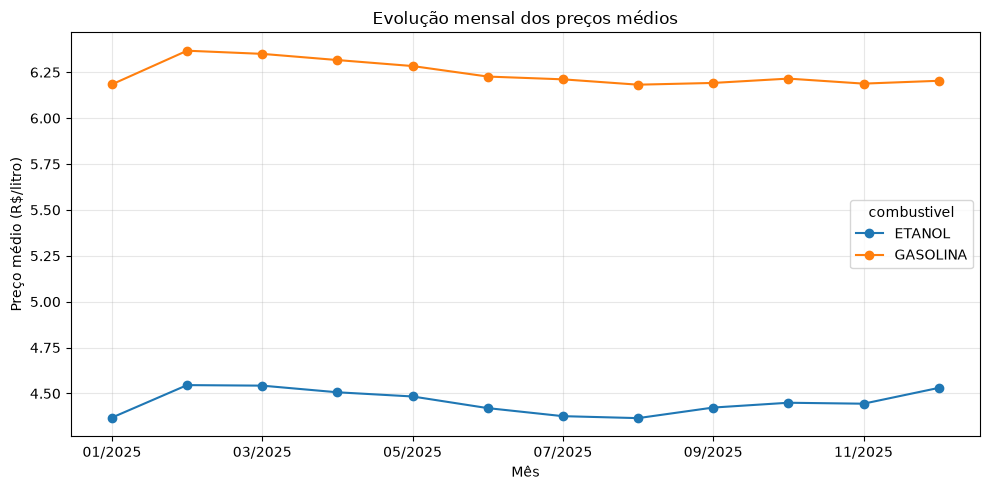

In [36]:
mensal = (
    df.groupby(
        ["data_referencia", "combustivel", "unidade_medida"],
        as_index=False
    )
    .agg(
        preco_medio=("preco_venda", "mean"),
        preco_minimo=("preco_venda", "min"),
        preco_maximo=("preco_venda", "max"),
        total_coletas=("preco_venda", "size"),
        postos_pesquisados=("revenda_id", "nunique"),
    )
    .sort_values(["data_referencia", "combustivel"])
)

mensal["mes"] = mensal["data_referencia"].dt.strftime("%m/%Y")

colunas = [
    "mes",
    "combustivel",
    "unidade_medida",
    "preco_medio",
    "preco_minimo",
    "preco_maximo",
    "total_coletas",
    "postos_pesquisados",
]

display(mensal[colunas].round(3))

# Comparação entre gasolina e etanol
comparacao = mensal[
    mensal["combustivel"].isin(["GASOLINA", "ETANOL"])
]

serie = comparacao.pivot(
    index="data_referencia",
    columns="combustivel",
    values="preco_medio"
).sort_index()

serie.index = serie.index.strftime("%m/%Y")
serie.index.name = "mes"

ax = serie.plot(
    marker="o",
    figsize=(10, 5)
)

ax.set(
    title="Evolução mensal dos preços médios",
    xlabel="Mês",
    ylabel="Preço médio (R$/litro)"
)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

5. Ranking de preços de gasolina por UF
Usamos o último mês disponível na base. Mostramos também a quantidade de coletas, pois os tamanhos das amostras diferem muito entre estados.

Mês de referência: 12/2025
5 maiores preços médios:


,preco_medio,coletas,postos
uf,,,
AC,7.411,39,17
AM,7.151,271,60
RO,6.831,259,65
RR,6.700,65,13
TO,6.585,138,65


5 menores preços médios:


,preco_medio,coletas,postos
uf,,,
PI,5.837,269,83
PB,5.909,317,82
MA,5.994,432,131
RN,6.035,189,64
AP,6.055,44,11


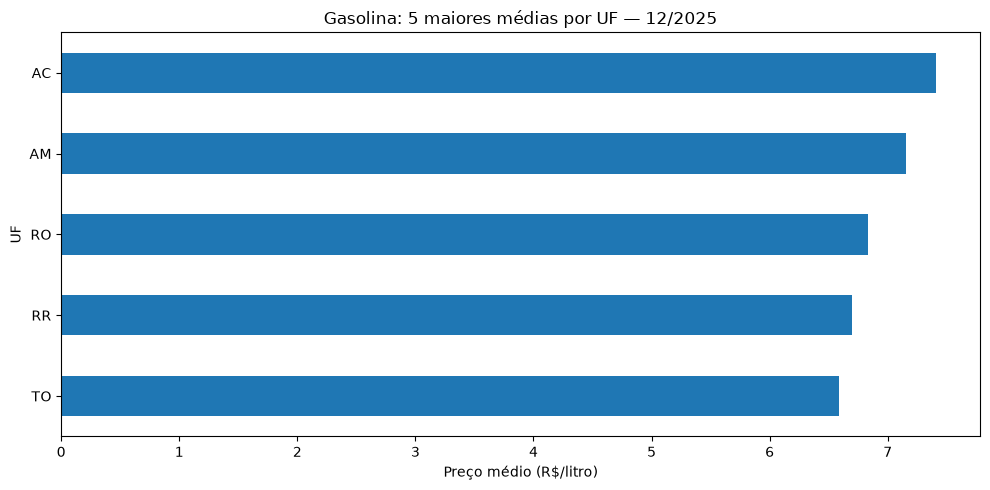

In [27]:
gasolina = df.loc[df["combustivel"] == "GASOLINA"].copy()
ultimo_mes = gasolina["mes"].max()

ranking = (
    gasolina.loc[gasolina["mes"] == ultimo_mes]
    .groupby("uf")
    .agg(preco_medio=("preco_venda", "mean"), coletas=("preco_venda", "size"),
         postos=("revenda_id", "nunique"))
    .sort_values("preco_medio", ascending=False)
)

print(f"Mês de referência: {ultimo_mes:%m/%Y}")
print("5 maiores preços médios:")
display(ranking.head(5).round(3))
print("5 menores preços médios:")
display(ranking.tail(5).sort_values("preco_medio").round(3))

ax = ranking.head(5).sort_values("preco_medio")["preco_medio"].plot.barh()
ax.set(title=f"Gasolina: 5 maiores médias por UF — {ultimo_mes:%m/%Y}",
       xlabel="Preço médio (R$/litro)", ylabel="UF")
plt.tight_layout()
plt.show()


6. Distribuição e dispersão dos preços
O histograma mostra onde se concentram as observações de gasolina. A estatística descritiva permite comparar média, mediana, quartis e extremos. Preços muito altos ou baixos não são automaticamente erros.

,gasolina_R$/litro
count,212423.000
mean,6.246
std,0.405
min,4.990
25%,5.990
50%,6.190
75%,6.470
max,9.290


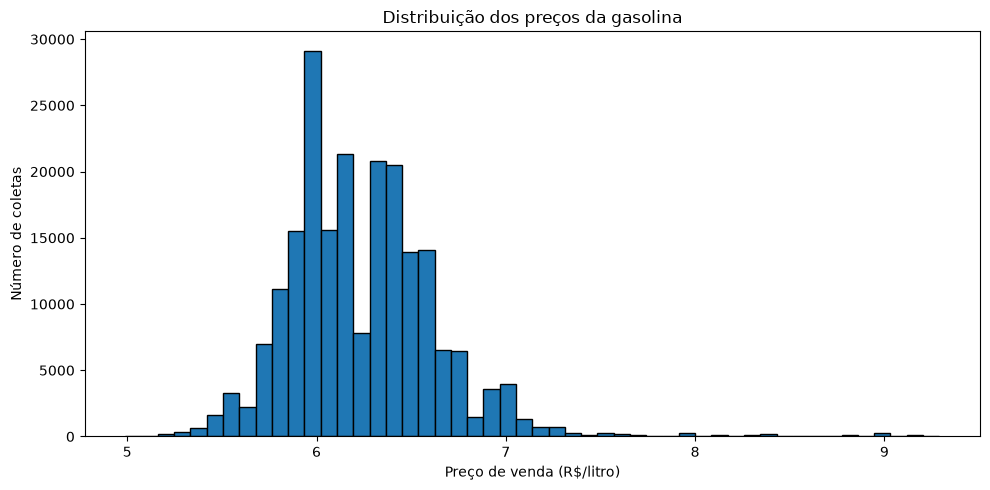

In [28]:
display(gasolina["preco_venda"].describe().to_frame(name="gasolina_R$/litro").round(3))

ax = gasolina["preco_venda"].plot.hist(bins=50, edgecolor="black")
ax.set(title="Distribuição dos preços da gasolina", xlabel="Preço de venda (R$/litro)",
       ylabel="Número de coletas")
plt.tight_layout()
plt.show()


8. Síntese automática dos insights
Os textos abaixo são calculados a partir da consulta atual, para continuarem corretos quando a Gold receber novos períodos.

In [41]:

from IPython.display import display, Markdown

# Filtrar gasolina comum
gasolina = df[df["combustivel"] == "GASOLINA"].copy()

gasolina["data_referencia"] = (
    pd.to_datetime(gasolina["data_coleta"])
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Evolução mensal da gasolina
mensal_gasolina = (
    gasolina.groupby("data_referencia")["preco_venda"]
    .mean()
    .sort_index()
)

preco_inicial = mensal_gasolina.iloc[0]
preco_final = mensal_gasolina.iloc[-1]

variacao_pct = (
    (preco_final - preco_inicial) / preco_inicial
) * 100

primeiro_mes = mensal_gasolina.index[0]
ultimo_mes = mensal_gasolina.index[-1]

# Ranking estadual do último mês
ranking = (
    gasolina[gasolina["data_referencia"] == ultimo_mes]
    .groupby("uf")
    .agg(
        preco_medio=("preco_venda", "mean"),
        coletas=("preco_venda", "size"),
    )
    .sort_values("preco_medio", ascending=False)
)

maior_uf = ranking.iloc[0]
menor_uf = ranking.iloc[-1]

maior_sigla = ranking.index[0]
menor_sigla = ranking.index[-1]

diferenca = (
    maior_uf["preco_medio"] - menor_uf["preco_medio"]
)

# Estatísticas gerais
mediana = gasolina["preco_venda"].median()
media = gasolina["preco_venda"].mean()

# Resumo automático
display(Markdown(f"""
### Principais achados

- **Cobertura:** {len(df):,} observações, {df['uf'].nunique()} UFs e {df['combustivel'].nunique()} tipos de combustíveis.

- **Evolução da gasolina:** a média das coletas passou de **R$ {preco_inicial:.3f}** para **R$ {preco_final:.3f}** ({variacao_pct:+.2f}%) entre {primeiro_mes:%m/%Y} e {ultimo_mes:%m/%Y}.

- **Desigualdade regional ({ultimo_mes:%m/%Y}):** **{maior_sigla}** apresentou a maior média (**R$ {maior_uf['preco_medio']:.3f}**, {int(maior_uf['coletas'])} coletas), enquanto **{menor_sigla}** apresentou a menor (**R$ {menor_uf['preco_medio']:.3f}**, {int(menor_uf['coletas'])} coletas). Diferença: **R$ {diferenca:.3f}/litro**.

- **Distribuição da gasolina:** média de **R$ {media:.3f}** e mediana de **R$ {mediana:.3f}**.

**Limitação:** diferenças no número e na composição das coletas podem afetar rankings e tendências. Os resultados descrevem a amostra de preços da ANP, não uma média ponderada por consumo.
"""))



### Principais achados

- **Cobertura:** 804,617 observações, 27 UFs e 6 tipos de combustíveis.

- **Evolução da gasolina:** a média das coletas passou de **R$ 6.184** para **R$ 6.203** (+0.31%) entre 01/2025 e 12/2025.

- **Desigualdade regional (12/2025):** **AC** apresentou a maior média (**R$ 7.411**, 39 coletas), enquanto **PI** apresentou a menor (**R$ 5.837**, 269 coletas). Diferença: **R$ 1.574/litro**.

- **Distribuição da gasolina:** média de **R$ 6.246** e mediana de **R$ 6.190**.

**Limitação:** diferenças no número e na composição das coletas podem afetar rankings e tendências. Os resultados descrevem a amostra de preços da ANP, não uma média ponderada por consumo.


In [37]:
import os
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

raiz = Path.cwd()

if not (raiz / ".env").exists():
    raiz = raiz.parent

load_dotenv(raiz / ".env")

url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("POSTGRES_USER", "etl_user"),
    password=os.getenv("POSTGRES_PASSWORD"),
    host=os.getenv("POSTGRES_HOST", "localhost"),
    port=int(os.getenv("POSTGRES_PORT", "5433")),
    database=os.getenv("POSTGRES_DB", "combustiveis_dw"),
)

engine = create_engine(url)

query = """
    SELECT
        mes,
        uf,
        combustivel,
        preco_medio,
        preco_minimo,
        preco_maximo,
        total_coletas,
        postos_pesquisados
    FROM gold.vw_preco_mensal_uf
    ORDER BY mes, uf, combustivel
"""

df_estados = pd.read_sql(query, engine)

df_estados["data_referencia"] = pd.to_datetime(df_estados["mes"])

df_estados["mes"] = (
    df_estados["data_referencia"].dt.strftime("%m/%Y")
)

for coluna in ["preco_medio", "preco_minimo", "preco_maximo"]:
    df_estados[coluna] = pd.to_numeric(df_estados[coluna])

print("Registros:", len(df_estados))
print("Estados:", df_estados["uf"].nunique())
print("Combustíveis:", df_estados["combustivel"].unique().tolist())

display(df_estados.drop(columns=["data_referencia"]).head(100))

Registros: 1824
Estados: 27
Combustíveis: ['DIESEL', 'DIESEL S10', 'ETANOL', 'GASOLINA', 'GASOLINA ADITIVADA', 'GNV']


,mes,uf,combustivel,preco_medio,preco_minimo,preco_maximo,total_coletas,postos_pesquisados
0,01/2025,AC,DIESEL,7.622,7.380,7.930,57,16
1,01/2025,AC,DIESEL S10,7.693,7.380,7.950,46,14
2,01/2025,AC,ETANOL,5.282,4.900,5.740,47,11
3,01/2025,AC,GASOLINA,7.497,7.230,7.750,71,17
4,01/2025,AC,GASOLINA ADITIVADA,7.566,7.290,7.930,64,16
...,...,...,...,...,...,...,...,...
95,01/2025,PR,DIESEL,6.018,5.590,6.530,520,172
96,01/2025,PR,DIESEL S10,6.121,5.590,6.990,774,255
97,01/2025,PR,ETANOL,4.380,3.690,4.990,1160,367
98,01/2025,PR,GASOLINA,6.253,5.690,6.830,1146,363


,uf,preco_medio,total_coletas,postos_pesquisados
0,AC,7.411,39,17
1,AM,7.151,271,60
2,RO,6.831,259,65
3,RR,6.700,65,13
4,TO,6.585,138,65
5,SE,6.463,160,36
6,PR,6.388,1263,380
7,DF,6.364,246,75
8,MT,6.357,381,123
9,GO,6.351,777,215


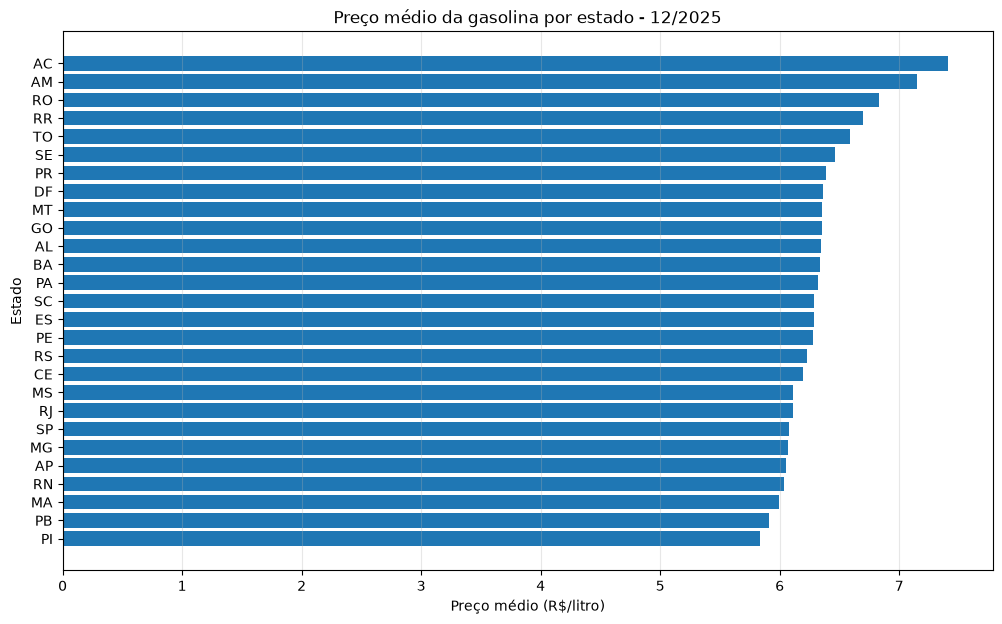

In [18]:
combustivel = "GASOLINA"

df_gasolina = df_estados[
    df_estados["combustivel"] == combustivel
].copy()

ultimo_mes = df_gasolina["mes"].max()

ranking = (
    df_gasolina[df_gasolina["mes"] == ultimo_mes]
    .sort_values("preco_medio", ascending=False)
)

display(
    ranking[
        ["uf", "preco_medio", "total_coletas", "postos_pesquisados"]
    ].reset_index(drop=True)
)

plt.figure(figsize=(12, 7))

plt.barh(
    ranking["uf"],
    ranking["preco_medio"],
)

plt.gca().invert_yaxis()
plt.title(f"Preço médio da gasolina por estado - {ultimo_mes:%m/%Y}")
plt.xlabel("Preço médio (R$/litro)")
plt.ylabel("Estado")
plt.grid(axis="x", alpha=0.3)

plt.show()

uf,BA,MG,PR,RJ,SP
mes,,,,,
01/2025,6.415,6.075,6.253,6.114,6.018
02/2025,6.566,6.253,6.545,6.236,6.184
03/2025,6.534,6.215,6.554,6.229,6.176
04/2025,6.440,6.209,6.521,6.213,6.150
05/2025,6.367,6.172,6.479,6.204,6.139
06/2025,6.404,6.127,6.432,6.132,6.075
07/2025,6.306,6.131,6.403,6.114,6.057
08/2025,6.259,6.104,6.401,6.073,6.044
09/2025,6.245,6.091,6.395,6.059,6.064


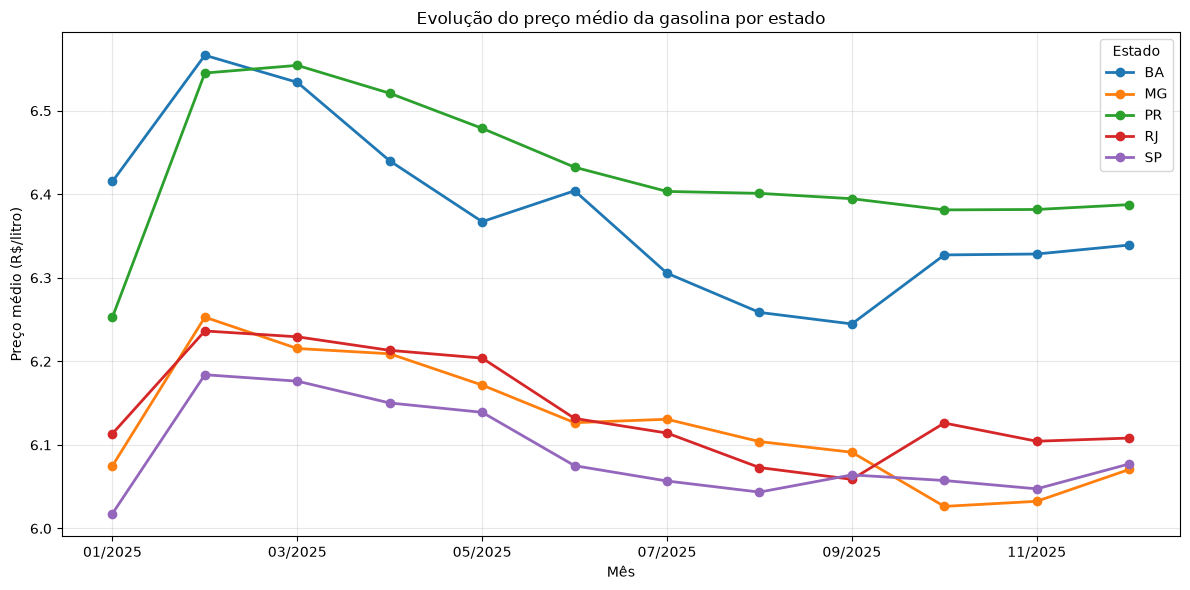

In [38]:
estados = ["SP", "RJ", "MG", "BA", "PR"]

df_gasolina = df_estados[
    df_estados["combustivel"] == "GASOLINA"
].copy()

evolucao = df_gasolina[
    df_gasolina["uf"].isin(estados)
]

tabela_evolucao = evolucao.pivot(
    index="data_referencia",
    columns="uf",
    values="preco_medio",
).sort_index()

tabela_evolucao.index = (
    tabela_evolucao.index.strftime("%m/%Y")
)

tabela_evolucao.index.name = "mes"

display(tabela_evolucao.round(3))

ax = tabela_evolucao.plot(
    figsize=(12, 6),
    marker="o",
    linewidth=2,
)

ax.set_title("Evolução do preço médio da gasolina por estado")
ax.set_xlabel("Mês")
ax.set_ylabel("Preço médio (R$/litro)")
ax.grid(alpha=0.3)

plt.legend(title="Estado")
plt.tight_layout()
plt.show()

,uf,preco_inicial,preco_final,variacao_percentual
6,DF,6.190,6.360,2.880
26,TO,6.430,6.580,2.390
17,PR,6.250,6.390,2.150
12,MT,6.220,6.360,2.130
22,RS,6.100,6.230,2.130
3,AP,5.930,6.060,2.090
24,SE,6.350,6.460,1.810
8,GO,6.270,6.350,1.360
25,SP,6.020,6.080,0.990
15,PE,6.240,6.280,0.720


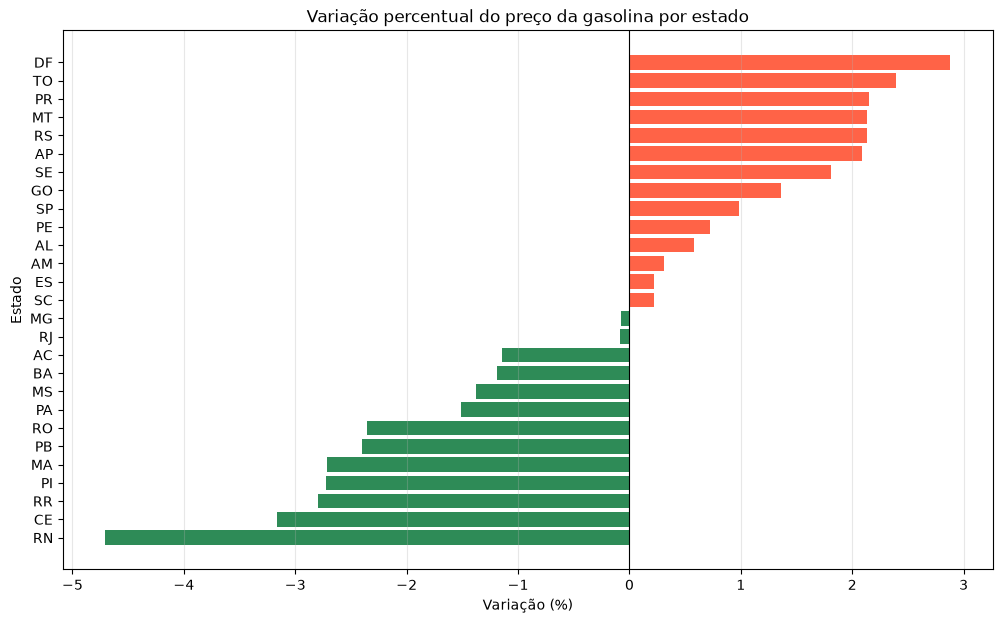

In [20]:
historico = df_gasolina.sort_values(["uf", "mes"])

variacao = (
    historico.groupby("uf")
    .agg(
        preco_inicial=("preco_medio", "first"),
        preco_final=("preco_medio", "last"),
        primeiro_mes=("mes", "first"),
        ultimo_mes=("mes", "last"),
        meses_observados=("mes", "nunique"),
    )
    .reset_index()
)

variacao = variacao[
    (variacao["meses_observados"] >= 2)
    & (variacao["preco_inicial"] > 0)
].copy()

variacao["variacao_percentual"] = (
    (variacao["preco_final"] / variacao["preco_inicial"] - 1) * 100
)

variacao = variacao.sort_values(
    "variacao_percentual",
    ascending=False,
)

display(
    variacao[
        ["uf", "preco_inicial", "preco_final", "variacao_percentual"]
    ].round(2)
)

plt.figure(figsize=(12, 7))

cores = [
    "tomato" if valor > 0 else "seagreen"
    for valor in variacao["variacao_percentual"]
]

plt.barh(
    variacao["uf"],
    variacao["variacao_percentual"],
    color=cores,
)

plt.axvline(0, color="black", linewidth=0.8)
plt.gca().invert_yaxis()
plt.title("Variação percentual do preço da gasolina por estado")
plt.xlabel("Variação (%)")
plt.ylabel("Estado")
plt.grid(axis="x", alpha=0.3)

plt.show()

In [22]:
resumo_estados = (
    df_gasolina.groupby("uf")
    .agg(
        preco_medio_periodo=("preco_medio", "mean"),
        menor_media_mensal=("preco_medio", "min"),
        maior_media_mensal=("preco_medio", "max"),
        desvio_padrao_mensal=("preco_medio", "std"),
        meses_analisados=("mes", "nunique"),
    )
    .sort_values("preco_medio_periodo", ascending=False)
)

display(resumo_estados.round(3))

,preco_medio_periodo,menor_media_mensal,maior_media_mensal,desvio_padrao_mensal,meses_analisados
uf,,,,,
AC,7.666,7.411,7.832,0.156,12
AM,7.223,7.009,7.417,0.123,12
RR,6.946,6.700,7.074,0.092,12
RO,6.912,6.744,7.143,0.113,12
SE,6.554,6.348,6.642,0.085,12
TO,6.533,6.431,6.639,0.059,12
DF,6.444,6.186,6.615,0.129,12
PR,6.428,6.253,6.554,0.085,12
PA,6.401,6.323,6.561,0.074,12
